# NYC Affordable Housing and Serious Road Crashes: Data Engineering and Visualization, Milestone 1


## Question
How are completed affordable housing and serious road crashes distributed across New York City's council districts, and do the two patterns line up? This is an exploration of association only. The data cannot show that either one affects the other.

## Key terms
- **Affordable housing:** apartments whose rent or price is set for lower and middle income households. It describes price, not construction quality.
- **New construction and preservation:** a new building with affordable apartments, or an existing building whose apartments are kept affordable.
- **Council district:** one of the 51 areas that elect the City Council. It is the shared key between the two datasets.
- **Severe-injury crash:** a crash in the SIRTA data with at least one severe injury or fatality.

## Datasets
- Housing (H2): Affordable Housing Production by Building, NYC Open Data. 9,551 rows, 41 columns. https://data.cityofnewyork.us/Housing-Development/Affordable-Housing-Production-by-Building/hg8x-zxpr/about_data
- Crashes (T4): Serious Injury Response, Tracking and Analysis Program (SIRTA), NYC Open Data. 13,754 rows, 23 columns. https://data.cityofnewyork.us/Transportation/Serious-Injury-Response-Tracking-Analysis-Program-/xeqp-qz8h/about_data
- Supporting data (used only to assign council districts): City Council Districts, NYC Department of City Planning, NYC Open Data (872g-cjhh), version 26c: https://data.cityofnewyork.us/d/872g-cjhh

## Why these two
Both have more than 9 columns, both carry coordinates, borough, council district and a date, and both are small enough to be downloaded and cleaned in full. They describe the same districts and years, so council district and year join them.


In [2]:
# cell 1
import pandas as pd

housing = pd.read_csv('Affordable_Housing_Production_by_Building_20261103.csv', low_memory=False)
crashes = pd.read_csv('Serious_Injury_Response,_Tracking_&_Analysis_Program_(SIRTA)_20261103.csv', low_memory=False)

print(housing.shape, crashes.shape)

(9551, 41) (13754, 23)


In [3]:
# cell 2
H = dict(boro='Borough', zip='Postcode', tract='Census Tract', nta='NTA - Neighborhood Tabulation Area',
         council='Council District', cb='Community Board', lat='Latitude', lon='Longitude',
         date='Building Completion Date')
C = dict(boro='Crash Borough', zip='ZipCode', tract='Census Tract (2020)',
         nta='Neighborhood Tabulation Area (NTA) (2020)', council='Council District',
         cb='Community Board', lat='Latitude', lon='Longitude', date='Crash Date')

## 1. Exploring the raw data
Before changing anything we measured missing values, duplicates, date ranges and possible join keys.

**Housing:** the unit-type columns are mostly empty (for example 6-bedroom units are 99.7% empty), which is expected because a building has only some unit types. Location fields (postcode, tract, NTA, latitude, longitude) are 20.5% empty. 1,666 buildings (17.4%) have no completion date.

**Crashes:** 444 rows are empty apart from location codes. Council district is 71.9% empty and coordinates are 21.0% empty. Highway Reference Marker (92.4%), Address (81.3%), BIN and BBL (79.7%) are mostly empty.

**Dates:** crashes run from January 2022 to June 2026. Housing completion dates run from 2014 to August 2026.

In [4]:
# cell 3
for name, df in [('housing', housing), ('crashes', crashes)]:
    print(name, df.shape, '| at least 9 columns:', df.shape[1] >= 9)
    print((df.isna().mean() * 100).round(1).sort_values(ascending=False).head(15), '\n')

housing (9551, 41) | at least 9 columns: True
6-BR+ Units                    99.7
5-BR Units                     99.2
4-BR Units                     94.1
Unknown-BR Units               92.8
Other Income Units             85.8
Moderate Income Units          82.3
Extremely Low Income Units     78.2
Middle Income Units            71.8
Counted Homeownership Units    71.4
Studio Units                   66.5
Very Low Income Units          64.4
3-BR Units                     64.1
Low Income Units               42.4
2-BR Units                     36.7
1-BR Units                     36.0
dtype: float64 

crashes (13754, 23) | at least 9 columns: True
Highway Reference Marker                              92.4
Address                                               81.3
Building Identification Number (BIN)                  79.7
Borough Block Lot (BBL)                               79.7
Neighborhood Tabulation Area (NTA) (2020)             71.9
Council District                                      7

In [5]:
# cell 4
# For each possible way to join the two datasets (borough, ZIP, census tract, neighbourhood,
rows = []
for key in ['boro', 'zip', 'tract', 'nta', 'council', 'cb', 'lat', 'lon', 'date']:
    rows.append({'key': key,
                 'housing_fill_%': round(housing[H[key]].notna().mean() * 100, 1),
                 'crashes_fill_%': round(crashes[C[key]].notna().mean() * 100, 1)})

print(pd.DataFrame(rows).to_string(index=False))

    key  housing_fill_%  crashes_fill_%
   boro           100.0            96.4
    zip            79.5            58.7
  tract            79.5            28.1
    nta            79.5            28.1
council           100.0            28.1
     cb           100.0            28.1
    lat            79.5            79.0
    lon            79.5            79.0
   date            82.6            96.8


In [6]:
# cell 5
# Turn the date text into real dates, so we can see which years both datasets cover.
# errors='coerce' marks anything unreadable as missing instead of stopping with an error.
housing['date_clean'] = pd.to_datetime(housing[H['date']], errors='coerce')
crashes['date_clean'] = pd.to_datetime(crashes[C['date']], errors='coerce')

# For each dataset: first date, last date, how many dates could not be read, and records per year.
# This is how the 2022-2025 window was chosen: crashes start in 2022, and 2026 is a partial year in both files.
for name, df in [('housing', housing), ('crashes', crashes)]:
    print(name, df['date_clean'].min(), df['date_clean'].max(), 'unparseable:', df['date_clean'].isna().sum())
    print(df['date_clean'].dt.year.value_counts().sort_index(), '\n')

# Other housing date columns, in case a different one overlaps better
for col in ['Project Start Date', 'Project Completion Date']:
    d = pd.to_datetime(housing[col], errors='coerce')
    print(col, d.min(), d.max(), 'missing %:', round(d.isna().mean() * 100, 1))

housing 2014-01-03 00:00:00 2026-08-21 00:00:00 unparseable: 1666
date_clean
2014.0    376
2015.0    290
2016.0    432
2017.0    830
2018.0    664
2019.0    862
2020.0    419
2021.0    581
2022.0    654
2023.0    806
2024.0    705
2025.0    792
2026.0    474
Name: count, dtype: int64 

crashes 2022-01-01 00:00:00 2026-06-30 00:00:00 unparseable: 444
date_clean
2022.0    2879
2023.0    3016
2024.0    3116
2025.0    2947
2026.0    1352
Name: count, dtype: int64 

Project Start Date 2014-01-03 00:00:00 2026-06-30 00:00:00 missing %: 0.0
Project Completion Date 2014-01-03 00:00:00 2026-08-11 00:00:00 missing %: 19.0


In [7]:
# cell 6
# Quality checks before any cleaning: duplicates, borough names, coordinates, text-in-number columns.
print('Duplicate rows:', housing.duplicated().sum(), crashes.duplicated().sum())
print('Repeated Collision ID:', crashes['Collision ID'].duplicated().sum())
print('Repeated Building ID:', housing['Building ID'].duplicated().sum())

print(housing[H['boro']].value_counts(dropna=False), '\n')
print(crashes[C['boro']].value_counts(dropna=False), '\n')

# Coordinates must fall inside NYC otherwise they are wrong or missing
for name, df, k in [('housing', housing, H), ('crashes', crashes, C)]:
    ok = df[k['lat']].between(40.4, 41.0) & df[k['lon']].between(-74.3, -73.6)
    print(name, 'coordinates outside NYC or missing:', (~ok).sum())

# Total Units is a string in housing: how many values are not numeric?
tu = pd.to_numeric(housing['Total Units'], errors='coerce')
print('Total Units non-numeric:', (tu.isna() & housing['Total Units'].notna()).sum())

# What kind of crashes are in T4?
print(crashes[['Total Non-Severe Injuries', 'Total Severe Injuries', 'Total Fatalities']].describe())
print('Crashes with no severe injury and no fatality:',
      ((crashes['Total Severe Injuries'] == 0) & (crashes['Total Fatalities'] == 0)).sum())

Duplicate rows: 0 3
Repeated Collision ID: 444
Repeated Building ID: 2072
Borough
Brooklyn         3649
Bronx            2630
Manhattan        1485
Queens           1342
Staten Island     445
Name: count, dtype: int64 

Crash Borough
Brooklyn         3954
Queens           3282
Manhattan        2733
Bronx            2617
Staten Island     669
NaN               499
Name: count, dtype: int64 

housing coordinates outside NYC or missing: 1958
crashes coordinates outside NYC or missing: 2886
Total Units non-numeric: 7
       Total Non-Severe Injuries  Total Severe Injuries  Total Fatalities
count               13310.000000           13310.000000      13310.000000
mean                    0.270473               1.011495          0.082795
std                     0.836031               0.451514          0.294304
min                     0.000000               0.000000          0.000000
25%                     0.000000               1.000000          0.000000
50%                     0.000000     

In [8]:
# cell 7
# Compare possible join keys: how many values do the two datasets share, and is the key dense enough?
def overlap(h_col, c_col, label):
    hs, cs = set(housing[h_col].dropna().unique()), set(crashes[c_col].dropna().unique())
    print(f'{label}: housing {len(hs)}, crashes {len(cs)}, shared {len(hs & cs)}')

overlap(H['zip'], C['zip'], 'ZIP')
overlap(H['council'], C['council'], 'Council district')
overlap(H['nta'], C['nta'], 'NTA name')

# Census tract is only unique within a borough, so build a combined key
housing['boro_up'] = housing[H['boro']].str.upper().str.strip()
crashes['boro_up'] = crashes[C['boro']].str.upper().str.strip()
housing['tract_key'] = housing['boro_up'] + '_' + housing[H['tract']].astype('Int64').astype(str)
crashes['tract_key'] = crashes['boro_up'] + '_' + crashes[C['tract']].astype('Int64').astype(str)
overlap('tract_key', 'tract_key', 'Borough + census tract')

# How dense would each aggregated table be?
# Council district gives the biggest cells (median 7 and 12), which is why it was chosen as the join key
for key_h, key_c, label in [(H['zip'], C['zip'], 'ZIP'), (H['council'], C['council'], 'Council district'),
                            (H['nta'], C['nta'], 'NTA')]:
    hg = housing.groupby([key_h, housing['date_clean'].dt.year]).size()
    cg = crashes.groupby([key_c, crashes['date_clean'].dt.year]).size()
    print(f'{label}-by-year cells: housing {len(hg)} (median {hg.median()}), crashes {len(cg)} (median {cg.median()})')

ZIP: housing 158, crashes 187, shared 155
Council district: housing 51, crashes 51, shared 51
NTA name: housing 168, crashes 224, shared 0
Borough + census tract: housing 1164, crashes 1941, shared 702
ZIP-by-year cells: housing 1007 (median 3.0), crashes 829 (median 7.0)
Council district-by-year cells: housing 627 (median 7.0), crashes 255 (median 12.0)
NTA-by-year cells: housing 1083 (median 3.0), crashes 910 (median 3.0)


In [9]:
# cell 8: confirm what the problem rows are

# Crashes: are the rows with no date the same as rows with no Collision ID?
no_id = crashes['Collision ID'].isna()
no_date = crashes['date_clean'].isna()
print('No Collision ID:', no_id.sum(), '| No/bad Crash Date:', no_date.sum(), '| both:', (no_id & no_date).sum())
print(crashes[no_date].notna().sum().sort_values(ascending=False).head(8))  # columns that still have values in those rows
print(crashes[no_date].head(3).T)

# Crashes: how many have coordinates but no council district / ZIP (recoverable by spatial join)?
has_coords = crashes['Latitude'].notna() & crashes['Longitude'].notna()
print('Coordinates but no council district:', (has_coords & crashes['Council District'].isna()).sum())
print('Coordinates but no ZIP:', (has_coords & crashes['ZipCode'].isna()).sum())
print('Crashes 2022-2025 with coordinates:', (has_coords & crashes['date_clean'].dt.year.between(2022, 2025)).sum())

# Housing: do the missing coordinates, ZIP, tract and NTA fall on the same rows?
geo_cols = ['Postcode', 'Census Tract', 'NTA - Neighborhood Tabulation Area', 'Latitude', 'Longitude']
print(housing[geo_cols].isna().all(axis=1).sum(), 'rows missing all five;',
      housing[geo_cols].isna().any(axis=1).sum(), 'rows missing at least one')

# Housing: are rows with no Building Completion Date just unfinished buildings?
no_comp = housing['date_clean'].isna()
print(housing.loc[no_comp, 'Reporting Construction Type'].value_counts(dropna=False))
print(housing.loc[~no_comp, 'Reporting Construction Type'].value_counts(dropna=False))

# Housing: repeated Building IDs (are they real duplicates or different records of the same building?)
dup_b = housing[housing.duplicated('Building ID', keep=False)].sort_values('Building ID')
print(dup_b[['Building ID', 'Project ID', 'Project Name', 'Reporting Construction Type',
             'All Counted Units', 'Total Units']].head(12))

# Housing: the non-numeric Total Units values
tu = pd.to_numeric(housing['Total Units'], errors='coerce')
print(housing.loc[tu.isna() & housing['Total Units'].notna(), 'Total Units'].tolist())

No Collision ID: 444 | No/bad Crash Date: 444 | both: 444
Neighborhood Tabulation Area (NTA) (2020)    444
Community Board                              444
Council District                             444
Census Tract (2020)                          444
Borough Block Lot (BBL)                      433
Building Identification Number (BIN)         433
Crash Time                                     0
Crash Police Precinct                          0
dtype: int64
                                                             46   \
Collision ID                                                 NaN   
Crash Date                                                   NaN   
Crash Time                                                   NaN   
Crash Police Precinct                                        NaN   
Crash Borough                                                NaN   
Total Non-Severe Injuries                                    NaN   
Total Severe Injuries                                        

## 2. Cleaning before integration

**Empty crash rows (444 removed).** They had no crash ID, date or injury counts, only location codes, so they describe no crash.

**Repeated Collision ID (1 removed).** One ID appeared twice with different dates. We kept the first row.

**Text numbers (7 fixed).** Total Units held values like "1,320". The commas were removed and the column was converted to numbers.

**Dates.** Both date columns were converted to dates, with unreadable values left missing. 1,666 buildings have no completion date, and for 1,653 of them the project completion date is also missing, so they are probably not completed yet. We did not invent dates. These buildings are left out of the time-based charts.

In [10]:
# cell 9
# crashes: confirm the empty rows, then drop them and exact duplicates
no_id = crashes['Collision ID'].isna()
no_date = crashes['date_clean'].isna()
no_injury = crashes['Total Severe Injuries'].isna()
print('no ID:', no_id.sum(), '| no date:', no_date.sum(), '| no injury count:', no_injury.sum())
# all 444 rows lack ID, date and injury counts together, so they describe no crash and are safe to remove
print('no ID + no date + no injury count:', (no_id & no_date & no_injury).sum())

crashes_clean = crashes[~no_date].drop_duplicates().reset_index(drop=True)
print('crashes kept:', len(crashes_clean),
      '| repeated Collision ID after cleaning:', crashes_clean['Collision ID'].duplicated().sum())

# housing: Total Units has thousands separators like '1,320'
housing['Total Units'] = pd.to_numeric(
    housing['Total Units'].astype(str).str.replace(',', '', regex=False), errors='coerce')
print('Total Units still missing:', housing['Total Units'].isna().sum())

# housing: are undated buildings also missing the project completion date?
# (almost always yes, so they cannot be placed in a year and are left out of year-based views)
proj_comp = pd.to_datetime(housing['Project Completion Date'], errors='coerce')
no_comp = housing['date_clean'].isna()
print('No building completion date:', no_comp.sum())
print('  project completion date also missing:', (no_comp & proj_comp.isna()).sum())
print('  project completion date present:', (no_comp & proj_comp.notna()).sum())

no ID: 444 | no date: 444 | no injury count: 444
no ID + no date + no injury count: 444
crashes kept: 13310 | repeated Collision ID after cleaning: 1
Total Units still missing: 0
No building completion date: 1666
  project completion date also missing: 1653
  project completion date present: 13


## 3. Assigning council districts from coordinates
Only 28.1% of crashes carry a council district in the file, but 79% have coordinates. We loaded the council district boundaries (City Council Districts, NYC Department of City Planning, version 26c) and checked which district contains each point. This is called a point-in-polygon spatial join.

We also compared the district written in the file with the one from the map. Housing agreed 99.9% of the time. Crashes agreed 96.5% overall, but only 77.5% in 2023. We did not find the reason, so 2023 is listed under limitations.

In [11]:
# cell 10
# Download the official City Council District boundaries (NYC Open Data 872g-cjhh) as map polygons.
# We need them because only 28.1% of crashes carry a council district in the file, while ~79% have coordinates,
# so the district can be recovered by checking which polygon each coordinate falls in (cell 11).
import geopandas as gpd
from shapely import wkt

COUNCIL_ID = '872g-cjhh'
try:
    council = gpd.read_file(f'https://data.cityofnewyork.us/resource/{COUNCIL_ID}.geojson?$limit=100')
except Exception as e:
    print('GeoJSON endpoint failed, using CSV instead:', e)
    raw = pd.read_csv(f'https://data.cityofnewyork.us/api/views/{COUNCIL_ID}/rows.csv?accessType=DOWNLOAD')
    geom_col = [c for c in raw.columns if 'geom' in c.lower()][0]
    council = gpd.GeoDataFrame(raw, geometry=raw[geom_col].apply(wkt.loads), crs='EPSG:4326')

print(council.shape, council.crs)
print(council.columns.tolist())

(51, 4) EPSG:4326
['coundist', 'shape_leng', 'shape_area', 'geometry']


In [12]:
DIST_COL = [c for c in council.columns if 'coun' in c.lower() and 'dist' in c.lower()][0]
council['council_new'] = pd.to_numeric(council[DIST_COL]).astype(int)
council = council[['council_new', 'geometry']].to_crs('EPSG:4326')
print(DIST_COL, council['council_new'].nunique(), 'districts')

coundist 51 districts


In [13]:
# cell 11
# Point-in-polygon join: give every crash and every building the council district whose boundary
# contains its coordinates, then test how well that agrees with the district already in the file.
def add_council_from_coords(df, lat, lon):
    """Point-in-polygon join: which current council district contains each coordinate?"""
    df = df.reset_index(drop=True)
    valid = df[lat].between(40.4, 41.0) & df[lon].between(-74.3, -73.6)
    pts = gpd.GeoDataFrame(index=df.index[valid],
                           geometry=gpd.points_from_xy(df.loc[valid, lon], df.loc[valid, lat]),
                           crs='EPSG:4326')
    joined = gpd.sjoin(pts, council, how='left', predicate='within')
    joined = joined[~joined.index.duplicated(keep='first')]   # a point on a border can match twice
    df['council_new'] = joined['council_new']
    return df

crashes_clean = add_council_from_coords(crashes_clean, 'Latitude', 'Longitude')
housing = add_council_from_coords(housing, 'Latitude', 'Longitude')

crashes_clean['year'] = crashes_clean['date_clean'].dt.year
housing['year'] = housing['date_clean'].dt.year

# coverage after recovery
print('Crashes with a council district after recovery %:',
      round(crashes_clean['council_new'].fillna(crashes_clean['Council District']).notna().mean() * 100, 1))

# agreement between the existing district value and the one from the current map
both = crashes_clean['Council District'].notna() & crashes_clean['council_new'].notna()
match = crashes_clean.loc[both, 'Council District'] == crashes_clean.loc[both, 'council_new']
print('\nCrashes: rows tested', both.sum(), '| overall agreement %:', round(match.mean() * 100, 1))
print(match.groupby(crashes_clean.loc[both, 'year']).mean().mul(100).round(1))

both_h = housing['Council District'].notna() & housing['council_new'].notna()
match_h = housing.loc[both_h, 'Council District'] == housing.loc[both_h, 'council_new']
print('\nHousing: rows tested', both_h.sum(), '| overall agreement %:', round(match_h.mean() * 100, 1))
print(match_h.groupby(housing.loc[both_h, 'year']).mean().mul(100).round(1))

Crashes with a council district after recovery %: 83.0

Crashes: rows tested 3224 | overall agreement %: 96.5
year
2022     99.1
2023     77.5
2024    100.0
2025    100.0
2026    100.0
dtype: float64

Housing: rows tested 7593 | overall agreement %: 99.9
year
2014.0    100.0
2015.0    100.0
2016.0    100.0
2017.0    100.0
2018.0    100.0
2019.0    100.0
2020.0    100.0
2021.0    100.0
2022.0    100.0
2023.0    100.0
2024.0    100.0
2025.0     99.5
2026.0     99.7
dtype: float64


In [14]:
# cell 12
# Checks that support the district rule used in cell 13.
# the one remaining repeated Collision ID
print(crashes_clean[crashes_clean['Collision ID'].duplicated(keep=False)].T)

# how many existing-district rows were tested per year in cell 11
print(crashes_clean.loc[both, 'year'].value_counts().sort_index())

# rows without coordinates but with an existing district, by year
has_new = crashes_clean['council_new'].notna()
has_old = crashes_clean['Council District'].notna()
print((~has_new & has_old).sum(), 'rows have no coordinates but an existing district')
print(crashes_clean.loc[~has_new & has_old, 'year'].value_counts().sort_index())
print((~has_new & ~has_old).sum(), 'rows have no district at all')

                                                                  2148   \
Collision ID                                                  4597666.0   
Crash Date                                                   01/13/2023   
Crash Time                                                        21:01   
Crash Police Precinct                                              44.0   
Crash Borough                                                     Bronx   
Total Non-Severe Injuries                                           0.0   
Total Severe Injuries                                               1.0   
Total Fatalities                                                    0.0   
Latitude                                                            NaN   
Longitude                                                           NaN   
On Street                                               WEST 170 STREET   
Cross Street                                                   Plaza Dr   
Address                  

## 4. Final district, borough and column decisions

**District rule.** Use the district from the coordinates. If a crash has no coordinates, use the file's own district only from 2024 on, where it matched the map 100%. Housing uses the file's value as a fallback. Final coverage is 82.4% for crashes and 100% for housing.

**Borough.** Names were stripped and standardised. Missing crash boroughs were filled from the district. 10 crashes still have none and are labelled Unknown.

**Blank unit counts.** A blank in a unit-type column means the building has none of that type, so it was filled with 0. 29 buildings had no counted units at all (zero rental and zero homeownership units), so their total was set to 0.

**Dropped columns.** Highway Reference Marker, Address, BIN and BBL (mostly empty) and the internal latitude and longitude columns (copies of other columns).

In [15]:
# cell 13
# drop the repeated Collision ID (keep the first row)
crashes_clean = crashes_clean.drop_duplicates('Collision ID').reset_index(drop=True)

# final council district: current-map district from coordinates; for rows without coordinates
# keep the file's own value only from 2024 on (it matched the current map 100% there)
has_new = crashes_clean['council_new'].notna()
has_old = crashes_clean['Council District'].notna()
use_old = ~has_new & has_old & (crashes_clean['year'] >= 2024)
crashes_clean['council_final'] = crashes_clean['council_new']
crashes_clean.loc[use_old, 'council_final'] = crashes_clean.loc[use_old, 'Council District']
crashes_clean['council_final'] = crashes_clean['council_final'].astype('Int64')

# housing: same rule (coordinates first, then the file's own value, which matches 99.9%)
housing['council_final'] = housing['council_new'].fillna(housing['Council District']).astype('Int64')

print('council coverage % - crashes:', round(crashes_clean['council_final'].notna().mean() * 100, 1),
      '| housing:', round(housing['council_final'].notna().mean() * 100, 1))

# borough: standardize spelling, then fill missing crash boroughs from the district
housing['borough_clean'] = housing['Borough'].str.strip().str.title()
crashes_clean['borough_clean'] = crashes_clean['Crash Borough'].str.strip().str.title()

n_boro = housing.groupby('council_final')['borough_clean'].nunique()
print('districts that span more than one borough:', (n_boro > 1).sum())
d2b_map = (housing[housing['council_final'].isin(n_boro[n_boro == 1].index)]
           .groupby('council_final')['borough_clean'].first())
d2b_map.index = d2b_map.index.astype(int)

fill = crashes_clean['borough_clean'].isna() & crashes_clean['council_final'].notna()
crashes_clean.loc[fill, 'borough_clean'] = crashes_clean.loc[fill, 'council_final'].astype(int).map(d2b_map)
print('crash rows still without borough:', crashes_clean['borough_clean'].isna().sum())

# housing: blank unit-breakdown columns mean "none of that type", so fill with 0
breakdown_cols = [c for c in housing.columns
                  if c.endswith('Units') and c not in ('Total Units', 'All Counted Units')]
housing[breakdown_cols] = housing[breakdown_cols].fillna(0)
print('All Counted Units missing:', housing['All Counted Units'].isna().sum())

# drop mostly-empty or redundant columns
drop_crash = ['Highway Reference Marker', 'Address', 'Building Identification Number (BIN)',
              'Borough Block Lot (BBL)', 'boro_up', 'tract_key']
drop_house = ['Latitude (Internal)', 'Longitude (Internal)', 'boro_up', 'tract_key']
crashes_clean = crashes_clean.drop(columns=[c for c in drop_crash if c in crashes_clean.columns])
housing = housing.drop(columns=[c for c in drop_house if c in housing.columns])

council coverage % - crashes: 82.4 | housing: 100.0
districts that span more than one borough: 3
crash rows still without borough: 10
All Counted Units missing: 29


## 5. Outliers
**Housing:** an IQR rule flags 1,249 buildings above 72 units. They are flagged but kept, because large projects are real. The largest, 711 Sea Girt HDFC, has 917 units.

**Crashes:** injury counts are mostly 0, so an IQR rule would flag every injury. Instead we used a domain rule: 10 or more injuries, or 3 or more fatalities, marks a mass-casualty crash (23 crashes). They are flagged but kept.

**Coordinates** outside the New York City bounding box are treated as missing.

In [16]:
# cell 14
def iqr_upper(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return q3 + 1.5 * (q3 - q1)

# housing: flag very large buildings, but keep them (large projects are real)
hi = iqr_upper(housing['All Counted Units'])
housing['units_outlier'] = housing['All Counted Units'] > hi
print('All Counted Units upper IQR bound:', hi, '| flagged:', housing['units_outlier'].sum())
print(housing.nlargest(5, 'All Counted Units')[['Project Name', 'Borough', 'All Counted Units', 'Total Units']])

# crashes: injury counts are mostly 0, so IQR would flag every non-zero value; use a domain rule
crashes_clean['mass_casualty'] = (
    (crashes_clean['Total Non-Severe Injuries'] + crashes_clean['Total Severe Injuries'] >= 10)
    | (crashes_clean['Total Fatalities'] >= 3))
print('mass-casualty crashes:', crashes_clean['mass_casualty'].sum())
print(crashes_clean.nlargest(5, 'Total Non-Severe Injuries')[
    ['Crash Date', 'borough_clean', 'Total Non-Severe Injuries', 'Total Severe Injuries', 'Total Fatalities']])

All Counted Units upper IQR bound: 72.0 | flagged: 1249
                      Project Name    Borough  All Counted Units  Total Units
6766             711 SEA GIRT HDFC     Queens              917.0          917
3107                    NORTH COVE  Manhattan              611.0          611
3474                 3333 BROADWAY  Manhattan              565.0          565
4610                 BRONX POINT A      Bronx              542.0          542
7470  JAMAICA CROSSING (HIGH-RISE)     Queens              539.0          539
mass-casualty crashes: 23
       Crash Date borough_clean  Total Non-Severe Injuries  \
2429   01/02/2023     Manhattan                       19.0   
12525  06/29/2026        Queens                       18.0   
3945   05/28/2023      Brooklyn                       15.0   
6676   10/21/2024      Brooklyn                       15.0   
5523   02/27/2024      Brooklyn                       14.0   

       Total Severe Injuries  Total Fatalities  
2429                     2.0

## 6. Integration

**Join key.** We compared candidate keys. ZIP shares 155 values, but the median housing count per ZIP and year is only 3. NTA names share none. Census tract overlaps on 702 keys only. Council district appears in both datasets (51 shared) with enough records per district and year (median 7 housing, 12 crashes), so council district plus year is the key.

**Method.** Both datasets are aggregated to one row per district and year, so the relationship is one to one. A full grid of 51 districts by 4 years (204 rows) is then left joined with each table, so no district-year disappears. A borough by year table (20 rows) is built the same way with an outer join, for measures that cannot be placed in districts.

**Window.** 2022 to 2025. The crash data starts in 2022, and 2026 is a partial year in both datasets.

In [17]:
# cell 15
# Result: one row per district and year (51 districts x 4 years = 204 rows)
WINDOW = (2022, 2025)   # full years present in both datasets

# housing: one row per building record, split affordable units by construction type
# (rows with no district or no year cannot be placed, so they are left out of this table)
h = housing[housing['year'].between(*WINDOW)].dropna(subset=['council_final']).copy()
h['year'] = h['year'].astype(int)
h['council_final'] = h['council_final'].astype(int)
h['new_units'] = h['All Counted Units'].where(h['Reporting Construction Type'] == 'New Construction', 0)
h['preserved_units'] = h['All Counted Units'].where(h['Reporting Construction Type'] == 'Preservation', 0)

c = crashes_clean[crashes_clean['year'].between(*WINDOW)].dropna(subset=['council_final']).copy()
c['year'] = c['year'].astype(int)
c['council_final'] = c['council_final'].astype(int)

housing_panel = h.groupby(['council_final', 'year']).agg(
    building_records=('All Counted Units', 'size'),
    affordable_units=('All Counted Units', 'sum'),
    new_units=('new_units', 'sum'),
    preserved_units=('preserved_units', 'sum')).reset_index()

crash_panel = c.groupby(['council_final', 'year']).agg(
    crashes=('Collision ID', 'count'),
    severe_injuries=('Total Severe Injuries', 'sum'),
    non_severe_injuries=('Total Non-Severe Injuries', 'sum'),
    fatalities=('Total Fatalities', 'sum')).reset_index()

# full grid of 51 districts x 4 years so no district-year is silently missing
districts = sorted(council['council_new'].unique())
grid = pd.MultiIndex.from_product(
    [districts, range(WINDOW[0], WINDOW[1] + 1)], names=['council_final', 'year']).to_frame(index=False)

# left joins keep every district-year, even when one dataset has nothing there
panel = (grid.merge(housing_panel, how='left', on=['council_final', 'year'])
             .merge(crash_panel, how='left', on=['council_final', 'year']))

# post-integration cleaning: a district-year with no record in a dataset had no events, so Not a Number(NaN) -> 0
count_cols = [col for col in panel.columns if col not in ('council_final', 'year')]
print('NaN created by the joins:', panel[count_cols].isna().sum().sum())
panel[count_cols] = panel[count_cols].fillna(0).astype(int)
panel['borough'] = panel['council_final'].map(d2b_map)

print(panel.shape, '| NaN left:', panel.isna().sum().sum())
print(panel.dtypes)
print(panel.describe().T)
print(panel[['affordable_units', 'new_units', 'crashes', 'severe_injuries', 'fatalities']]
      .corr(method='spearman').round(2))

NaN created by the joins: 24
(204, 11) | NaN left: 12
council_final           int64
year                    int64
building_records        int64
affordable_units        int64
new_units               int64
preserved_units         int64
crashes                 int64
severe_injuries         int64
non_severe_injuries     int64
fatalities              int64
borough                object
dtype: object
                     count         mean         std     min      25%     50%  \
council_final        204.0    26.000000   14.755812     1.0    13.00    26.0   
year                 204.0  2023.500000    1.120784  2022.0  2022.75  2023.5   
building_records     204.0    14.495098   12.805286     0.0     5.00    11.0   
affordable_units     204.0   496.318627  884.589355     0.0    36.00   230.5   
new_units            204.0   238.352941  305.091124     0.0    12.50   101.5   
preserved_units      204.0   257.965686  806.231185     0.0     0.00    12.0   
crashes              204.0    47.867647   

## 7. Cleaning after integration

**Missing values from the joins (24).** A district-year with no record in one dataset had no events there, so these were set to 0, not treated as unknown.

**Districts that span boroughs.** Districts 8, 34 and 50 cross borough lines (district 8 is 51% Bronx and 49% Manhattan). Each is assigned its dominant borough and flagged with spans_boroughs.

**Building ID.** 1,949 housing records (20.4%) have no Building ID, and none of them has coordinates, so their district comes from the file. A unique count would skip them, so buildings are counted as records (building_records). 180 rows share a Building ID and unit count with another row. We kept them because they belong to different projects.

**Result.** The district table has 204 rows and no missing values.

In [18]:
# cell 16
import numpy as np

# 1) housing: 29 rows with no 'All Counted Units' - inspect, then treat as 0 (not counted toward the plan)
miss = housing[housing['All Counted Units'].isna()]
print(len(miss), 'rows')
print(miss['Extended Affordability Only'].value_counts(dropna=False))
print(miss[['Counted Rental Units', 'Counted Homeownership Units']].sum())
housing['All Counted Units'] = housing['All Counted Units'].fillna(0)

# 2) one borough per district for the dashboard filter: dominant borough, plus a flag
geo = pd.concat([housing[['council_final', 'borough_clean']],
                 crashes_clean[['council_final', 'borough_clean']]]).dropna()
geo['council_final'] = geo['council_final'].astype(int)
share = (geo.groupby('council_final')['borough_clean'].value_counts(normalize=True)
         .rename('share').reset_index())
dominant = (share.sort_values('share', ascending=False)
                 .drop_duplicates('council_final').set_index('council_final')['borough_clean'])
multi = [int(d) for d in n_boro[n_boro > 1].index]
print('multi-borough districts:', multi)
print(share[share['council_final'].isin(multi)].round(2))

panel['borough'] = panel['council_final'].map(dominant)
panel['spans_boroughs'] = panel['council_final'].isin(multi)
print('panel NaN left:', panel.isna().sum().sum())

# 3) crash rows still without a borough: label them so dropdowns do not break
crashes_clean['borough_clean'] = crashes_clean['borough_clean'].fillna('Unknown')

# 4) derived columns for the website filters
crashes_clean['hour'] = pd.to_datetime(crashes_clean['Crash Time'], format='%H:%M', errors='coerce').dt.hour
crashes_clean['weekday'] = crashes_clean['date_clean'].dt.day_name()
crashes_clean['severity'] = np.where(crashes_clean['Total Fatalities'] > 0, 'Fatal', 'Severe injury')
print('crash hour unparseable:', crashes_clean['hour'].isna().sum())

income_cols = ['Extremely Low Income Units', 'Very Low Income Units', 'Low Income Units',
               'Moderate Income Units', 'Middle Income Units', 'Other Income Units']
housing['main_income_band'] = housing[income_cols].idxmax(axis=1).str.replace(' Income Units', '', regex=False)
housing.loc[housing[income_cols].sum(axis=1) == 0, 'main_income_band'] = 'Not specified'
print(housing['main_income_band'].value_counts())

# 5) bias check: do crashes with no district differ from the rest?
# (they are more often fatal and concentrated in 2024)
has_d = crashes_clean['council_final'].notna()
for col in ['borough_clean', 'year', 'severity']:
    comp = pd.concat([crashes_clean.loc[has_d, col].value_counts(normalize=True).rename('with district'),
                      crashes_clean.loc[~has_d, col].value_counts(normalize=True).rename('without district')],
                     axis=1)
    print((comp * 100).round(1), '\n')

29 rows
Extended Affordability Only
No    29
Name: count, dtype: int64
Counted Rental Units           0.0
Counted Homeownership Units    0.0
dtype: float64
multi-borough districts: [8, 34, 50]
    council_final  borough_clean  share
7               8          Bronx   0.51
8               8      Manhattan   0.49
35             34       Brooklyn   0.92
36             34         Queens   0.08
54             50  Staten Island   0.94
55             50       Brooklyn   0.06
panel NaN left: 0
crash hour unparseable: 0
main_income_band
Low              3695
Middle           2255
Very Low         1726
Extremely Low    1048
Moderate          794
Not specified      29
Other               4
Name: count, dtype: int64
               with district  without district
borough_clean                                 
Brooklyn                30.3              26.7
Queens                  24.7              26.2
Manhattan               20.3              21.4
Bronx                   19.7              19.4
Stat

In [19]:
# standardise street names: upper case, single spaces, and a final abbreviation spelled out
import re

SUFFIX = {'AVE': 'AVENUE', 'AV': 'AVENUE', 'ST': 'STREET', 'RD': 'ROAD', 'BLVD': 'BOULEVARD',
          'PKWY': 'PARKWAY', 'PKY': 'PARKWAY', 'DR': 'DRIVE', 'PL': 'PLACE', 'EXPY': 'EXPRESSWAY',
          'HWY': 'HIGHWAY', 'LN': 'LANE', 'CT': 'COURT', 'TPKE': 'TURNPIKE', 'BRG': 'BRIDGE',
          'TER': 'TERRACE', 'SQ': 'SQUARE'}


def clean_street(x):
    if not isinstance(x, str):
        return x
    words = re.sub(r'\s+', ' ', x.strip().upper()).split(' ')
    if len(words) > 1 and words[-1] in SUFFIX:      # only the last word, so "ST NICHOLAS AVENUE" is safe
        words[-1] = SUFFIX[words[-1]]
    return ' '.join(words)

# distinct names before and after (2,952 -> 2,286 in the full file, so the same streets merge)
before = crashes_clean['On Street'].nunique()
crashes_clean['On Street'] = crashes_clean['On Street'].map(clean_street)
print('distinct street names:', before, '->', crashes_clean['On Street'].nunique())

distinct street names: 2952 -> 2286


## Saved files
The cleaned data is saved in the data folder for the website:
- housing_clean.csv: cleaned housing records, 2022 to 2025
- crashes_clean.csv: cleaned crash records, 2022 to 2025
- panel_district_year.csv: one row per council district and year (204 rows)
- panel_borough_year.csv: one row per borough and year (20 rows)
- council_districts.geojson: simplified district boundaries for the map

In [20]:
# cell 17
import os
os.makedirs('data', exist_ok=True)
WINDOW = (2022, 2025)   # full years in both datasets, so 2026 partial data cannot mislead

h_web = housing[housing['year'].between(*WINDOW)].copy()
h_web['year'] = h_web['year'].astype(int)
h_web = h_web[['Project ID', 'Project Name', 'Building ID', 'borough_clean', 'council_final', 'year',
               'Latitude', 'Longitude', 'Reporting Construction Type', 'main_income_band',
               'All Counted Units', 'units_outlier']]

c_web = crashes_clean[crashes_clean['year'].between(*WINDOW)].copy()
c_web['year'] = c_web['year'].astype(int)
c_web = c_web[['Collision ID', 'date_clean', 'year', 'weekday', 'hour', 'borough_clean', 'council_final',
               'Latitude', 'Longitude', 'On Street', 'severity', 'Total Severe Injuries',
               'Total Non-Severe Injuries', 'Total Fatalities', 'mass_casualty']]

h_web.to_csv('data/housing_clean.csv', index=False)
c_web.to_csv('data/crashes_clean.csv', index=False)
panel.to_csv('data/panel_district_year.csv', index=False)
council.to_file('data/council_districts.geojson', driver='GeoJSON')
print(h_web.shape, c_web.shape, panel.shape)

(2957, 12) (11958, 15) (204, 12)


Checking how complete the district table is, by year and severity.

In [21]:
# cell 18: how incomplete is the district panel, by year and severity?
cc = crashes_clean.copy()
cc['has_district'] = cc['council_final'].notna()
cc['has_coords'] = cc['Latitude'].notna() & cc['Longitude'].notna()

# coverage is lowest in 2024 (67%) and very low for fatal crashes in 2023 to 2026, so district totals are lower bounds
print('% of crashes with a district, by year:')
print(cc.groupby('year')['has_district'].mean().mul(100).round(1))
print('\n% with a district, year x severity:')
print(cc.pivot_table(index='year', columns='severity', values='has_district', aggfunc='mean').mul(100).round(1))
print('\ncrash counts, year x severity:')
print(cc.pivot_table(index='year', columns='severity', values='Collision ID', aggfunc='count'))
# only about 20% of fatal crashes have coordinates, which is why district charts use severe-injury crashes
print('\n% with coordinates, by severity:')
print(cc.groupby('severity')['has_coords'].mean().mul(100).round(1))

# what is available for the crashes with no district? (for the limitations text)
print('\n% of unlocated crashes with street / ZIP information:')
print(cc.loc[~cc['has_district'], ['On Street', 'Cross Street', 'ZipCode']].notna().mean().mul(100).round(1))

# share of 2022-2025 fatalities that reach the district panel
in_window = cc['year'].between(2022, 2025)
print('\nfatalities 2022-2025 overall:', int(cc.loc[in_window, 'Total Fatalities'].sum()),
      '| in the district panel:', int(panel['fatalities'].sum()))

# optional: shrink the boundary file for faster loading on the website
council_small = council.copy()
council_small['geometry'] = council_small.geometry.simplify(0.0002, preserve_topology=True)
council_small.to_file('data/council_districts.geojson', driver='GeoJSON')

% of crashes with a district, by year:
year
2022    88.9
2023    81.5
2024    67.0
2025    90.2
2026    89.4
Name: has_district, dtype: float64

% with a district, year x severity:
severity  Fatal  Severe injury
year                          
2022       83.7           89.4
2023        0.0           88.4
2024        1.7           72.3
2025        3.3           96.9
2026        2.5           98.0

crash counts, year x severity:
severity  Fatal  Severe injury
year                          
2022        245           2634
2023        237           2779
2024        232           2884
2025        211           2736
2026        121           1230

% with coordinates, by severity:
severity
Fatal            19.7
Severe injury    86.9
Name: has_coords, dtype: float64

% of unlocated crashes with street / ZIP information:
On Street       88.5
Cross Street    61.6
ZipCode         50.1
dtype: float64

fatalities 2022-2025 overall: 975 | in the district panel: 224


Borough by year table, built from the record tables because fatalities cannot be placed in districts.

In [22]:
# cell 19: borough-by-year table built from the record tables (no district needed)
# Fatal crashes rarely have a district, so borough totals are built straight from the crash and housing records.
WINDOW = (2022, 2025)

c = crashes_clean[crashes_clean['year'].between(*WINDOW)].copy()
c['year'] = c['year'].astype(int)
h = housing[housing['year'].between(*WINDOW)].copy()
h['year'] = h['year'].astype(int)
h['new_units'] = h['All Counted Units'].where(h['Reporting Construction Type'] == 'New Construction', 0)
h['preserved_units'] = h['All Counted Units'].where(h['Reporting Construction Type'] == 'Preservation', 0)

# crashes per borough and year (crashes with an Unknown borough are left out; there are only 10)
crash_b = c[c['borough_clean'] != 'Unknown'].groupby(['borough_clean', 'year']).agg(
    crashes=('Collision ID', 'count'),
    fatal_crashes=('severity', lambda s: (s == 'Fatal').sum()),
    fatalities=('Total Fatalities', 'sum'),
    severe_injuries=('Total Severe Injuries', 'sum')).reset_index()

housing_b = h.groupby(['borough_clean', 'year']).agg(
    building_records=('All Counted Units', 'size'),
    affordable_units=('All Counted Units', 'sum'),
    new_units=('new_units', 'sum'),
    preserved_units=('preserved_units', 'sum')).reset_index()

# outer join keeps every borough-year; a missing side means no events, so 0
panel_borough = crash_b.merge(housing_b, how='outer', on=['borough_clean', 'year']).fillna(0)
panel_borough[panel_borough.columns[2:]] = panel_borough[panel_borough.columns[2:]].astype(int)
print(panel_borough.shape)   # expect 20 rows (5 boroughs x 4 years)
print(panel_borough)
panel_borough.to_csv('data/panel_borough_year.csv', index=False)

(20, 10)
    borough_clean  year  crashes  fatal_crashes  fatalities  severe_injuries  \
0           Bronx  2022      600             53          55              600   
1           Bronx  2023      600             46          46              600   
2           Bronx  2024      622             47          52              638   
3           Bronx  2025      543             32          33              559   
4        Brooklyn  2022      885             76          76              866   
5        Brooklyn  2023      874             62          66              871   
6        Brooklyn  2024      919             65          65              916   
7        Brooklyn  2025      879             70          76              895   
8       Manhattan  2022      570             35          40              575   
9       Manhattan  2023      653             38          39              654   
10      Manhattan  2024      639             39          44              630   
11      Manhattan  2025      58

In [23]:
# Final quality check on the cleaned tables: missing values, category spellings, impossible values.
h_cols = ['Building ID', 'borough_clean', 'council_final', 'year', 'Reporting Construction Type',
          'main_income_band', 'All Counted Units', 'Latitude', 'Longitude']
c_cols = ['Collision ID', 'borough_clean', 'council_final', 'year', 'weekday', 'hour', 'severity',
          'Total Severe Injuries', 'Total Fatalities', 'Latitude', 'Longitude']
print('housing missing %:'); print((housing[h_cols].isna().mean() * 100).round(1))
print('crashes missing %:'); print((crashes_clean[c_cols].isna().mean() * 100).round(1))

# category columns: check for spelling variants or unexpected values
for col in ['borough_clean', 'Reporting Construction Type', 'main_income_band']:
    print(housing[col].value_counts(dropna=False), '\n')
for col in ['borough_clean', 'severity', 'weekday']:
    print(crashes_clean[col].value_counts(dropna=False), '\n')

# impossible values: all of these should be 0 or empty
print('negative units:', (housing['All Counted Units'] < 0).sum())
print('negative injury/fatality values:',
      (crashes_clean[['Total Severe Injuries', 'Total Non-Severe Injuries', 'Total Fatalities']] < 0).sum().sum())
print('crash hours outside 0-23:', (~crashes_clean['hour'].between(0, 23)).sum())
print('single-value columns:', [c for c in housing.columns if housing[c].nunique(dropna=False) == 1],
      [c for c in crashes_clean.columns if crashes_clean[c].nunique(dropna=False) == 1])

housing missing %:
Building ID                    20.4
borough_clean                   0.0
council_final                   0.0
year                           17.4
Reporting Construction Type     0.0
main_income_band                0.0
All Counted Units               0.0
Latitude                       20.5
Longitude                      20.5
dtype: float64
crashes missing %:
Collision ID              0.0
borough_clean             0.0
council_final            17.6
year                      0.0
weekday                   0.0
hour                      0.0
severity                  0.0
Total Severe Injuries     0.0
Total Fatalities          0.0
Latitude                 18.3
Longitude                18.3
dtype: float64
borough_clean
Brooklyn         3649
Bronx            2630
Manhattan        1485
Queens           1342
Staten Island     445
Name: count, dtype: int64 

Reporting Construction Type
Preservation        4785
New Construction    4766
Name: count, dtype: int64 

main_income_band
Low

Building ID check. It supports the Building ID decision in section 7.

In [24]:
has_id = housing['Building ID'].notna()
print('rows with no Building ID:', (~has_id).sum())
# rows that share both ID and unit count with another row (possible duplicates)
d = housing[has_id & housing.duplicated(['Building ID', 'All Counted Units'], keep=False)]
print(len(d), 'rows with an ID share ID and units with another row')
# rows with no ID also have no coordinates and often no year, so they cannot be matched or placed on a map
print(pd.crosstab(housing['Building ID'].isna(), housing['year'].isna(), rownames=['no ID'], colnames=['no year']))
print(pd.crosstab(housing['Building ID'].isna(), housing['Latitude'].isna(), rownames=['no ID'], colnames=['no coords']))

rows with no Building ID: 1949
180 rows with an ID share ID and units with another row
no year  False  True 
no ID                
False     6006   1596
True      1879     70
no coords  False  True 
no ID                  
False       7593      9
True           0   1949


## 8. Cleaning summary
What changed in each dataset and why.

In [25]:
def n(x):
    return f'{int(x):,}'

crash_empty = int(crashes['date_clean'].isna().sum())
crash_after = len(crashes_clean)

summary = pd.DataFrame([
    # dataset, cleaning step, rows affected, reason
    ('Crashes (T4)', 'Rows in the original file',                          n(len(crashes)),   'Starting point'),
    ('Crashes (T4)', 'Empty rows removed',                                 n(crash_empty),    'No crash ID, date or injury counts, only location codes'),
    ('Crashes (T4)', 'Repeated crash ID removed',                          n(len(crashes) - crash_empty - crash_after), 'Same Collision ID appeared twice'),
    ('Crashes (T4)', 'Rows kept after cleaning',                           n(crash_after),    'Final crash table'),
    ('Crashes (T4)', 'Rows given a council district from coordinates',     n(crashes_clean['council_new'].notna().sum()), 'Point-in-polygon join with the current council map'),
    ('Crashes (T4)', 'Share of rows with a council district',              f"{crashes_clean['council_final'].notna().mean() * 100:.1f}%", 'Remaining rows have no usable location'),

    ('Housing (H2)', 'Rows in the original file',                          n(len(housing)),   'Starting point (no rows removed)'),
    ('Housing (H2)', 'Unit totals converted from text to numbers',         n(7),              'Values like "1,320" contained a comma'),
    ('Housing (H2)', 'Missing counted units set to 0',                     n(29),             'These buildings had no counted affordable units'),
    ('Housing (H2)', 'Rows given a council district from coordinates',     n(housing['council_new'].notna().sum()), 'Point-in-polygon join with the current council map'),
    ('Housing (H2)', 'Share of rows with a council district',              f"{housing['council_final'].notna().mean() * 100:.1f}%", "File's own district used where coordinates were missing"),
    ('Housing (H2)', 'Records with no Building ID (kept)',                 n(housing['Building ID'].isna().sum()), 'None has coordinates; district taken from the file; counted as building records'),
], columns=['Dataset', 'Cleaning step', 'Rows affected', 'Reason'])

summary

,Dataset,Cleaning step,Rows affected,Reason
0,Crashes (T4),Rows in the original file,"13,754",Starting point
1,Crashes (T4),Empty rows removed,444,"No crash ID, date or injury counts, only locat..."
2,Crashes (T4),Repeated crash ID removed,1,Same Collision ID appeared twice
3,Crashes (T4),Rows kept after cleaning,"13,309",Final crash table
4,Crashes (T4),Rows given a council district from coordinates,"10,841",Point-in-polygon join with the current council...
5,Crashes (T4),Share of rows with a council district,82.4%,Remaining rows have no usable location
6,Housing (H2),Rows in the original file,"9,551",Starting point (no rows removed)
7,Housing (H2),Unit totals converted from text to numbers,7,"Values like ""1,320"" contained a comma"
8,Housing (H2),Missing counted units set to 0,29,These buildings had no counted affordable units
9,Housing (H2),Rows given a council district from coordinates,"7,593",Point-in-polygon join with the current council...


## 9. Research questions and visualizations
Each member answers two questions below. Every chart is described as an association, never as a cause. District charts use severe-injury crashes, because fatal crashes rarely have a district (see limitations).

### Question 1: At what hours and on which weekdays do serious crashes happen?
**Member:** Ahmed Alaa

**Data used:** c_web
**Suggested chart:** heatmap of hour by weekday


In [26]:
import pandas as pd
import geopandas as gpd

BASE = 'https://raw.githubusercontent.com/ahmed-roushdy16004392/data-engineering-project-1/main/Data/'

h_web   = pd.read_csv(BASE + 'housing_clean.csv')
c_web   = pd.read_csv(BASE + 'crashes_clean.csv')
panel_d = pd.read_csv(BASE + 'panel_district_year.csv')
panel_b = pd.read_csv(BASE + 'panel_borough_year.csv')
districts = gpd.read_file(BASE + 'council_districts.geojson')

In [27]:
import plotly.express as px

# check how weekday is stored before drawing
print(c_web['weekday'].unique())
print(sorted(c_web['hour'].dropna().unique()))

['Saturday' 'Sunday' 'Monday' 'Tuesday' 'Wednesday' 'Thursday' 'Friday']
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]


In [28]:
# cell A2 (use when weekday holds names)
days = ['Saturday', 'Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']

grid = (c_web.pivot_table(index='weekday', columns='hour', values='Collision ID', aggfunc='count')
              .reindex(index=days, columns=range(24))
              .fillna(0))

fig = px.imshow(grid, aspect='auto', color_continuous_scale='Reds',
                labels=dict(x='Hour of day (0-23)', y='Weekday', color='Serious crashes'),
                title='Serious crashes (severe-injury and fatal) by hour and weekday, 2022-2025')
fig.show()

**Why this chart:** a heatmap fits two categorical axes (weekday and hour of day) with a count in each cell, so the pattern across both is visible at once. Darker means more serious crashes (severe-injury and fatal), 2022-2025.

**What the chart shows:** serious crashes peak in the afternoon rush, with 17:00 the busiest hour (765 crashes) followed by 18:00 and 15:00. Weekday totals are fairly even (Friday 1,832, Tuesday 1,613). Weekends differ at night: between midnight and 4 am Sunday has 430 crashes and Saturday 401, against 131 to 240 on other days.

**Limits:** the single darkest cell is Saturday at hour 0 (126 crashes). Some crashes recorded at exactly 00:00 may have an unknown time, so this cell may be inflated. These are counts, not rates, and they don't show why crashes happen.

### Question 2: How did affordable units completed each year change by borough, split into new and preserved?
**Member:** Seif Moustapha

**Data used:** panel_b
**Suggested chart:** stacked bars by borough and year (new vs preserved)


In [29]:
# Create a copy of the borough panel
housing_chart = panel_b[
    ['borough_clean', 'year', 'new_units', 'preserved_units']
].copy()

# Convert numerical columns to numeric format
housing_chart['year'] = pd.to_numeric(
    housing_chart['year'], errors='coerce'
)

housing_chart['new_units'] = pd.to_numeric(
    housing_chart['new_units'], errors='coerce'
)

housing_chart['preserved_units'] = pd.to_numeric(
    housing_chart['preserved_units'], errors='coerce'
)

# Remove rows without borough or year
housing_chart = housing_chart.dropna(
    subset=['borough_clean', 'year']
)

# Check for duplicate borough-year combinations
print("Duplicate borough-year records:",
      housing_chart.duplicated(['borough_clean', 'year']).sum())

# Aggregate in case duplicate borough-year records exist
housing_chart = (
    housing_chart.groupby(
        ['borough_clean', 'year'],
        as_index=False
    )[['new_units', 'preserved_units']]
    .sum(min_count=1)
)

display(housing_chart)

Duplicate borough-year records: 0


,borough_clean,year,new_units,preserved_units
0,Bronx,2022,2800,9206
1,Bronx,2023,5240,12182
2,Bronx,2024,4388,4985
3,Bronx,2025,5089,1954
4,Brooklyn,2022,3056,413
5,Brooklyn,2023,4199,2847
6,Brooklyn,2024,3650,1329
7,Brooklyn,2025,5477,546
8,Manhattan,2022,1242,1454
9,Manhattan,2023,950,2752


In [30]:
# Reshape data for stacked bar chart
housing_long = housing_chart.melt(
    id_vars=['borough_clean', 'year'],
    value_vars=['new_units', 'preserved_units'],
    var_name='Housing Type',
    value_name='Affordable Units'
)

# Make category names more readable
housing_long['Housing Type'] = housing_long['Housing Type'].replace({
    'new_units': 'New Units',
    'preserved_units': 'Preserved Units'
})

# Create chart
fig_q2 = px.bar(
    housing_long,
    x='borough_clean',
    y='Affordable Units',
    color='Housing Type',
    facet_col='year',
    facet_col_wrap=2,
    barmode='stack',
    title='Affordable Housing Units Completed by Borough (2022–2025)',
    labels={
        'borough_clean': 'Borough',
        'Affordable Units': 'Number of Affordable Units',
        'Housing Type': 'Housing Category',
        'year': 'Year'
    },
    color_discrete_map={
        'New Units': '#2878B5',
        'Preserved Units': '#F4A261'
    }
)

fig_q2.update_layout(
    template='plotly_white',
    height=750,
    width=1100,
    legend_title='Housing Type',
    title_x=0.5
)

fig_q2.update_xaxes(tickangle=-30)

fig_q2.show()

**Why this chart:** stacked bars show each borough's total completed affordable units and how much of it is new construction versus preservation, with one panel per year so years can be compared.

**What the chart shows:** The chart compares affordable housing units completed in each NYC borough from 2022 to 2025, split into new construction and preservation. The Bronx completed the most preserved units in 2022 and 2023 (9,206 and 12,182), Brooklyn's new construction was highest in 2025 (5,477), and Queens' preserved units jumped from 407 in 2024 to 4,930 in 2025. Staten Island stays small throughout.

**Limits:** The chart presents absolute unit counts rather than rates relative to population or existing housing stock, and therefore does not account for differences in borough size.

### Question 3: Is there a seasonal pattern? How do serious crashes (severe-injury and fatal) vary by month from 2022 to 2025?
**Member:** Seif Moustapha

**Data used:** c_web
**Suggested chart:** line chart by month, one line per severity


In [31]:
crash_chart = c_web[
    ['Collision ID', 'date_clean', 'severity']
].copy()

# Convert dates
crash_chart['date_clean'] = pd.to_datetime(
    crash_chart['date_clean'],
    errors='coerce'
)

# Standardize severity labels
crash_chart['severity'] = (
    crash_chart['severity']
    .astype(str)
    .str.strip()
    .str.lower()
)

# Keep 2022–2025
crash_chart = crash_chart[
    crash_chart['date_clean'].dt.year.between(2022, 2025)
].copy()

# Keep only the two serious crash categories
crash_chart = crash_chart[
    crash_chart['severity'].isin([
        'severe injury',
        'fatal'
    ])
].copy()

# Check duplicate collision IDs
print(
    "Duplicate collision IDs:",
    crash_chart['Collision ID'].duplicated().sum()
)

# Extract month
crash_chart['Month'] = (
    crash_chart['date_clean'].dt.month
)

# Standardize display names
crash_chart['Severity'] = crash_chart['severity'].map({
    'severe injury': 'Severe Injury',
    'fatal': 'Fatal'
})

print(crash_chart['Severity'].value_counts())

Duplicate collision IDs: 0
Severity
Severe Injury    11033
Fatal              925
Name: count, dtype: int64


In [32]:
# Creating line chart
monthly_crashes = (
    crash_chart.groupby(['Month', 'Severity'])
    ['Collision ID']
    .nunique()
    .reset_index(name='Crash Count')
)

# Ensure every month and severity combination exists
all_combinations = pd.MultiIndex.from_product(
    [
        range(1, 13),
        ['Severe Injury', 'Fatal']
    ],
    names=['Month', 'Severity']
)

monthly_crashes = (
    monthly_crashes
    .set_index(['Month', 'Severity'])
    .reindex(all_combinations, fill_value=0)
    .reset_index()
)

print(monthly_crashes)

    Month       Severity  Crash Count
0       1  Severe Injury          658
1       1          Fatal           65
2       2  Severe Injury          671
3       2          Fatal           70
4       3  Severe Injury          813
5       3          Fatal           61
6       4  Severe Injury          735
7       4          Fatal           58
8       5  Severe Injury         1077
9       5          Fatal           79
10      6  Severe Injury         1014
11      6          Fatal           82
12      7  Severe Injury         1134
13      7          Fatal           95
14      8  Severe Injury         1066
15      8          Fatal           98
16      9  Severe Injury         1087
17      9          Fatal           72
18     10  Severe Injury         1042
19     10          Fatal           94
20     11  Severe Injury          900
21     11          Fatal           80
22     12  Severe Injury          836
23     12          Fatal           71


In [33]:
crash_chart['Year'] = (
    crash_chart['date_clean'].dt.year
)

yearly_monthly_crashes = (
    crash_chart.groupby(
        ['Year', 'Month', 'Severity']
    )['Collision ID']
    .nunique()
    .reset_index(name='Crash Count')
)

fig = px.line(
    yearly_monthly_crashes,
    x='Month',
    y='Crash Count',
    color='Year',
    facet_row='Severity',
    markers=True,
    title='Monthly Serious Crash Trends by Year and Severity',
    labels={
        'Month': 'Month',
        'Crash Count': 'Number of Crashes',
        'Year': 'Year'
    }
)

fig.update_layout(
    template='plotly_white',
    height=700,
    title_x=0.5
)

fig.show()

**Why this chart:** a line chart suits a count measured over ordered months. One line per year lets us see whether the same months peak every year, and separate panels keep the much smaller fatal counts readable.

**What the chart shows:** The chart suggests a seasonal pattern in severe-injury crashes, with counts generally increasing from the beginning of the year and reaching higher levels between May and September, followed by a decline toward the end of the year. Fatal crashes show considerably lower monthly counts and more irregular fluctuations, without a consistent peak month across 2022–2025. Overall, severe-injury crashes appear to follow a more noticeable mid-year pattern than fatal crashes.

**Limits:** These figures represent monthly crash counts rather than rates adjusted for traffic volume or exposure, so they show associations and do not establish why crashes increase or decrease during particular months.

### Question 4: Which council districts have the most severe-injury?
**Member:** Ahmed Alaa

**Data used:** panel_d, districts
**Suggested chart:** map of the 51 districts coloured by crashes


In [34]:
d4 = (panel_d.groupby('council_final', as_index=False)['severe_injuries'].sum()
              .rename(columns={'council_final': 'council_new'}))
d4['council_new'] = d4['council_new'].astype(int)

dist = districts.copy()
dist['council_new'] = dist['council_new'].astype(int)

fig = px.choropleth(d4, geojson=dist.__geo_interface__, locations='council_new',
                    featureidkey='properties.council_new', color='severe_injuries',
                    color_continuous_scale='Reds',
                    labels={'severe_injuries': 'Severe injuries', 'council_new': 'Council district'},
                    title='Severe injuries by council district, 2022-2025')
fig.update_geos(fitbounds='locations', visible=False)
fig.show()

In [35]:
top10 = d4.sort_values('severe_injuries', ascending=False).head(10)
fig2 = px.bar(top10, x=top10['council_new'].astype(str), y='severe_injuries',
              labels={'x': 'Council district', 'severe_injuries': 'Severe injuries'},
              title='Top 10 council districts by severe injuries, 2022-2025')
fig2.show()

**Why this chart:** a map shows where the injuries are across the 51 districts, and the top-10 bar chart ranks the leaders so exact values can be compared.

**What the chart shows:** District 8 has the most severe injuries (358), then district 3 (324) and district 17 (299).

**Limits:** only crashes that could be placed in a district are counted (about 82%), so totals are lower bounds. Counts are not rates: larger or busier districts naturally have more.

### Question 5: Do districts with more affordable units also tend to have more severe-injury?
**Member:** Abdelrahman Elakkad

**Data used:** panel_d
**Suggested chart:** scatter plot, one dot per district, coloured by borough


In [36]:
# Question 5
# One row per council district: the panel is district-by-year, and the question compares districts.
dist_totals = (
    panel_d.groupby(["council_final", "borough"], as_index=False)[["affordable_units", "severe_injuries"]]
    .sum()
)
dist_totals["council_final"] = dist_totals["council_final"].astype(int)

rho = dist_totals["affordable_units"].rank().corr(dist_totals["severe_injuries"].rank())
most = dist_totals.nlargest(13, "affordable_units")["severe_injuries"].mean()
least = dist_totals.nsmallest(13, "affordable_units")["severe_injuries"].mean()

# Subtract each district's own average, so this correlation is about years inside a
# district rather than about which districts are larger.
demeaned = panel_d.copy()
for col in ["affordable_units", "severe_injuries"]:
    demeaned[col] = demeaned[col] - demeaned.groupby("council_final")[col].transform("mean")
within_rho = demeaned["affordable_units"].rank().corr(demeaned["severe_injuries"].rank())

print(f"Districts: {len(dist_totals)}")
print(f"Spearman rank correlation, across districts: {rho:.2f}")
print(f"Mean severe injuries, 13 districts with the most units: {most:.0f}")
print(f"Mean severe injuries, 13 districts with the least units: {least:.0f}")
print(f"Spearman rank correlation, year-to-year inside a district: {within_rho:.2f}")

# Label the districts discussed in the write-up. The rest stay unlabeled so the chart is readable.
label_ids = {12, 8, 3, 4, 31}
dist_totals["label"] = dist_totals["council_final"].map(lambda d: str(d) if d in label_ids else "")
print(dist_totals.loc[dist_totals["council_final"].isin(label_ids),
                      ["council_final", "borough", "affordable_units", "severe_injuries"]]
      .sort_values("affordable_units", ascending=False)
      .to_string(index=False))

fig = px.scatter(
    dist_totals,
    x="affordable_units",
    y="severe_injuries",
    color="borough",
    text="label",
    hover_name="council_final",
    title=f"Council districts, 2022-2025: affordable units and severe injuries (rank correlation {rho:.2f})",
    labels={
        "affordable_units": "Affordable units completed",
        "severe_injuries": "Severe injuries",
        "borough": "Borough",
        "council_final": "Council district",
    },
    category_orders={"borough": ["Bronx", "Brooklyn", "Manhattan", "Queens", "Staten Island"]},
    color_discrete_map={
        "Bronx": "#E45756",
        "Brooklyn": "#4C78A8",
        "Manhattan": "#F58518",
        "Queens": "#54A24B",
        "Staten Island": "#B279A2",
    },
)
fig.update_traces(textposition="top center", marker={"size": 11})
fig.add_vline(x=dist_totals["affordable_units"].median(), line_dash="dash", line_color="grey")
fig.add_hline(y=dist_totals["severe_injuries"].median(), line_dash="dash", line_color="grey")
fig.update_layout(template="plotly_white", height=560, width=900, title_x=0.5)
fig.show()

Districts: 51
Spearman rank correlation, across districts: 0.50
Mean severe injuries, 13 districts with the most units: 245
Mean severe injuries, 13 districts with the least units: 170
Spearman rank correlation, year-to-year inside a district: 0.05
 council_final   borough  affordable_units  severe_injuries
            12     Bronx             17064              208
             8     Bronx              5662              358
            31    Queens              3921              177
             3 Manhattan              1885              324
             4 Manhattan               733              259


**Why this chart:** both measures are district totals, so one dot per district shows whether high housing and high injuries tend to land on the same districts. Borough colour shows whether that pattern belongs to one borough. The dashed lines are the medians, and the numbered dots are the districts named below.

**What the chart shows:** Across the 51 districts, those with more affordable units tend to have more severe injuries, loosely (Spearman rank correlation 0.50): the 13 districts with the most units average 245 severe injuries, against 170 for the 13 with the least. District 8 is high on both (5,662 units, 358 severe injuries), while District 12 has by far the most units (17,064) but only 208 severe injuries. Inside each district, years with more housing were not years with more injuries (rank correlation 0.05).

**Limits:** these are counts, not rates, so a larger or busier district can be high on both without housing causing crashes. Crashes that could not be placed in a district are missing, and fatal crashes are left out because most of them have no district.

### Question 6: Where do severe-injury crashes and new-construction buildings sit on the same map?
**Member:** Abdelrahman Elakkad

**Data used:** c_web, h_web
**Suggested chart:** dot map with two colours, one for crashes and one for new-construction buildings


In [43]:
# Question 6
# Keep severe-injury crashes only. Fatal crashes are a separate severity and are mostly missing coordinates.
severe = c_web[c_web["severity"].eq("Severe injury")].copy()
new_buildings = h_web[h_web["Reporting Construction Type"].eq("New Construction")].copy()

severe_mapped = severe.dropna(subset=["Latitude", "Longitude"])
buildings_mapped = new_buildings.dropna(subset=["Latitude", "Longitude"])

print(f"Severe-injury crashes: {len(severe):,} | with coordinates: {len(severe_mapped):,} "
      f"({100 * severe['Latitude'].isna().mean():.0f}% missing)")
print(f"New-construction buildings: {len(new_buildings):,} | with coordinates: {len(buildings_mapped):,} "
      f"({100 * new_buildings['Latitude'].isna().mean():.0f}% missing)")
print("Mapped new-construction buildings by borough:")
print(buildings_mapped["borough_clean"].value_counts().to_string())
print("Mapped severe-injury crashes by borough:")
print(severe_mapped["borough_clean"].value_counts().to_string())

top_buildings = set(buildings_mapped.groupby("council_final").size().nlargest(10).index.astype(int))
top_crashes = set(severe_mapped.dropna(subset=["council_final"]).groupby("council_final").size().nlargest(10).index.astype(int))
print("Top 10 districts by new-construction buildings:", sorted(top_buildings))
print("Top 10 districts by severe-injury crashes:", sorted(top_crashes))
print("In both top 10s:", sorted(top_buildings & top_crashes))

points = pd.concat([
    severe_mapped.assign(place="Severe-injury crash"),
    buildings_mapped.assign(place="New-construction building"),
], ignore_index=True)

fig = px.scatter_map(
    points,
    lat="Latitude",
    lon="Longitude",
    color="place",
    hover_data={"borough_clean": True, "council_final": True, "year": True, "Latitude": False, "Longitude": False},
    zoom=9,
    center={"lat": 40.71, "lon": -73.98},
    map_style="carto-positron",
    title="Severe-injury crashes and new-construction affordable buildings, 2022-2025",
    labels={"place": "", "borough_clean": "Borough", "council_final": "Council district", "year": "Year"},
    color_discrete_map={
        "Severe-injury crash": "#E45756",
        "New-construction building": "#4C78A8",
    },
    opacity=0.65,
    height=700,
)
fig.update_traces(marker={"size": 4}, selector={"name": "Severe-injury crash"})
fig.update_traces(marker={"size": 8}, selector={"name": "New-construction building"})
fig.update_layout(margin={"l": 0, "r": 0, "t": 50, "b": 0}, title_x=0.5)
fig.show()

Severe-injury crashes: 11,033 | with coordinates: 9,477 (14% missing)
New-construction buildings: 1,886 | with coordinates: 1,460 (23% missing)
Mapped new-construction buildings by borough:
borough_clean
Brooklyn         662
Bronx            492
Queens           216
Manhattan         85
Staten Island      5
Mapped severe-injury crashes by borough:
borough_clean
Brooklyn         2890
Queens           2359
Manhattan        1907
Bronx            1878
Staten Island     442
Unknown             1
Top 10 districts by new-construction buildings: [14, 15, 16, 17, 34, 36, 37, 40, 41, 45]
Top 10 districts by severe-injury crashes: [3, 4, 8, 15, 16, 17, 20, 26, 33, 41]
In both top 10s: [15, 16, 17, 41]


**Why this chart:** the question is about place. A map shows whether the two sets of points occupy the same parts of the city, which a district total cannot show. Blue dots are drawn larger so the buildings stay visible on top of the crashes.

**What the chart shows:** Severe-injury crashes with coordinates (9,477 of 11,033) cover every borough, while the mapped new-construction buildings (1,460 of 1,886) are more concentrated: 45% are in Brooklyn and 34% in the Bronx. The two sets overlap in the Bronx and parts of Brooklyn, and Districts 15, 16, 17 and 41 are in the top 10 for both mapped buildings and mapped crashes. Sharing a map shows a shared location only.

**Limits:** 14% of severe-injury crashes and 23% of new-construction buildings have no coordinates, and the gap is uneven (only 5 of Staten Island's 78 new-construction buildings have coordinates). Preservation buildings are not on this map, dots are not adjusted for street length or traffic, and a cluster is not evidence that new buildings cause crashes.

### Question 7: Do the 10 districts with the most affordable units overlap with the 10 districts with the most serious crashes?
**Member:** Steven Elias

**Data used:** panel_d
**Suggested chart:** two ranked bar charts side by side


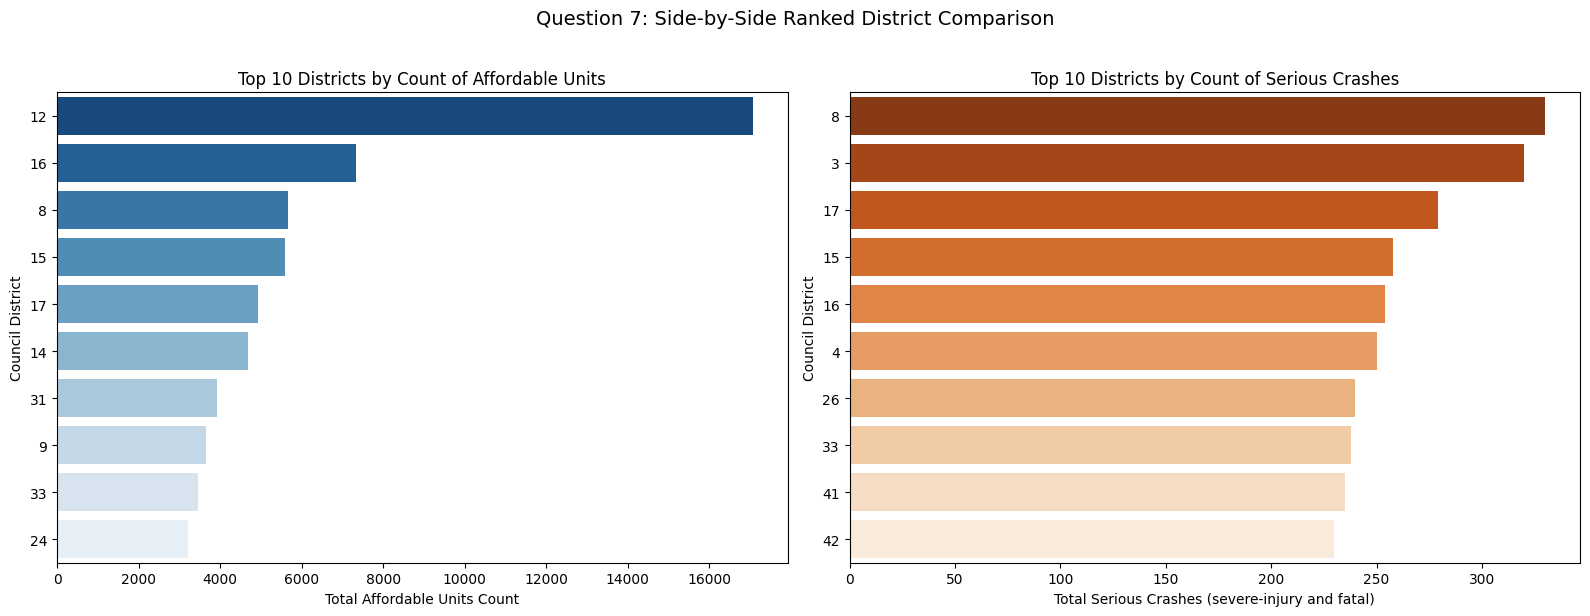

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Group datasets to get top 10
top_10_housing = h_web.groupby('council_final')['All Counted Units'].sum().reset_index()
top_10_housing = top_10_housing.sort_values(by='All Counted Units', ascending=False).head(10)

top_10_crashes = c_web.groupby('council_final').size().reset_index(name='crash_count')
top_10_crashes = top_10_crashes.sort_values(by='crash_count', ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left Plot: Top 10 Districts by Affordable Units
sns.barplot(
    data=top_10_housing,
    x='All Counted Units',
    y=top_10_housing['council_final'].astype(int).astype(str),
    ax=axes[0],
    palette='Blues_r',
    hue=top_10_housing['council_final'].astype(int).astype(str),
    legend=False
)
axes[0].set_title('Top 10 Districts by Count of Affordable Units', fontsize=12)
axes[0].set_xlabel('Total Affordable Units Count')
axes[0].set_ylabel('Council District')

# Right Plot: Top 10 Districts by Serious Crashes
sns.barplot(
    data=top_10_crashes,
    x='crash_count',
    y=top_10_crashes['council_final'].astype(int).astype(str),
    ax=axes[1],
    palette='Oranges_r',
    hue=top_10_crashes['council_final'].astype(int).astype(str),
    legend=False
)
axes[1].set_title('Top 10 Districts by Count of Serious Crashes', fontsize=12)
axes[1].set_xlabel('Total Serious Crashes (severe-injury and fatal)')
axes[1].set_ylabel('Council District')

plt.suptitle('Question 7: Side-by-Side Ranked District Comparison', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

**Why these charts:** two ranked horizontal bar charts side by side let the reader compare the two top-10 lists directly. Horizontal bars keep the district numbers readable, and the two colours show that they are different measures.

**What the chart shows:** Five districts (8, 15, 16, 17 and 33) appear in both top-10 lists, so half of the districts with the most completed affordable units are also among those with the most serious crashes. This is an association between counts and does not show that housing causes crashes, or the reverse.

**Limits:** these are raw counts per district, not rates per resident or per road mile, so large or dense districts rank higher in both lists. Only crashes placed in a district are counted.

### Question 8: Which 10 streets appear most often in serious crashes?
**Member:** Omar Nasr

**Data used:** c_web
**Suggested chart:** horizontal bar chart of the top 10 streets


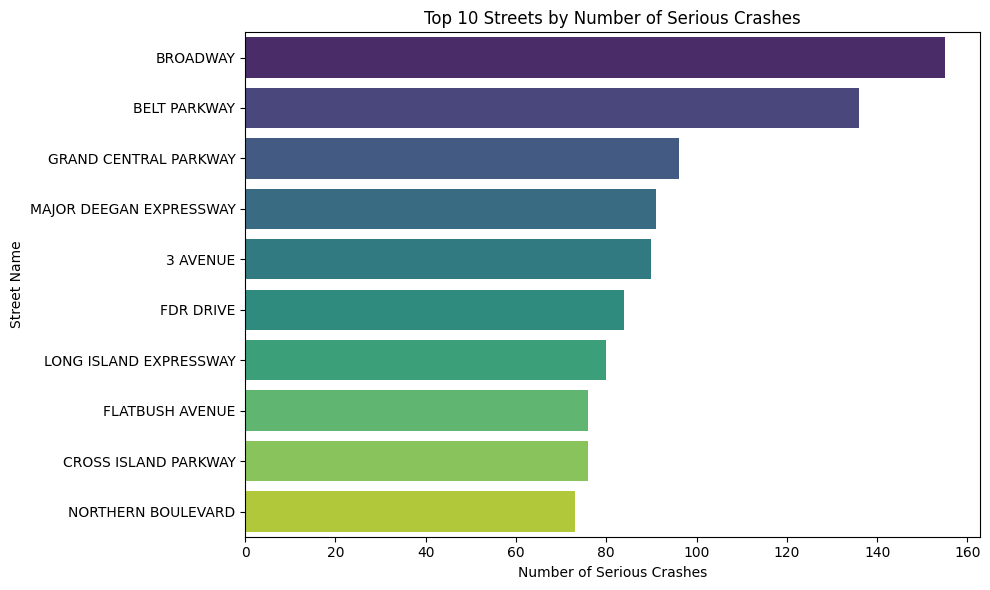

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count crashes per street and select the top 10
top_streets = c_web['On Street'].value_counts().head(10).reset_index()
top_streets.columns = ['Street Name', 'Crash Count']

# Plotting the horizontal bar chart
plt.figure(figsize=(10, 6))
sns.barplot(x='Crash Count', y='Street Name', data=top_streets,
            hue='Street Name', palette='viridis', legend=False)
plt.title('Top 10 Streets by Number of Serious Crashes')
plt.xlabel('Number of Serious Crashes')
plt.ylabel('Street Name')
plt.tight_layout()
plt.show()

**Why this chart:** street names are long labels, so horizontal bars keep them readable, and sorting by count makes the ranking clear at a glance.

**What the chart shows:** Broadway has the most serious crashes (155), followed by Belt Parkway (136), Grand Central Parkway (96) and Major Deegan Expressway (91). Six of the top 10 are parkways, expressways or drives (Belt Parkway, Grand Central Parkway, Major Deegan Expressway, FDR Drive, Long Island Expressway and Cross Island Parkway). This is an association between these roads and more crashes, not a measure of how dangerous each road is.

**Limits:** counts are not adjusted for traffic volume or street length, so long, busy roads rank high. About 19% of crashes have no street name and are left out, and streets with the same name in different boroughs are counted together (Broadway appears in all five boroughs).

### Question 9: Which districts saw the biggest increase or decrease in serious crashes between 2022 and 2025?
**Member:** Steven Elias

**Data used:** panel_d
**Suggested chart:** diverging bar chart comparing 2022 and 2025 only


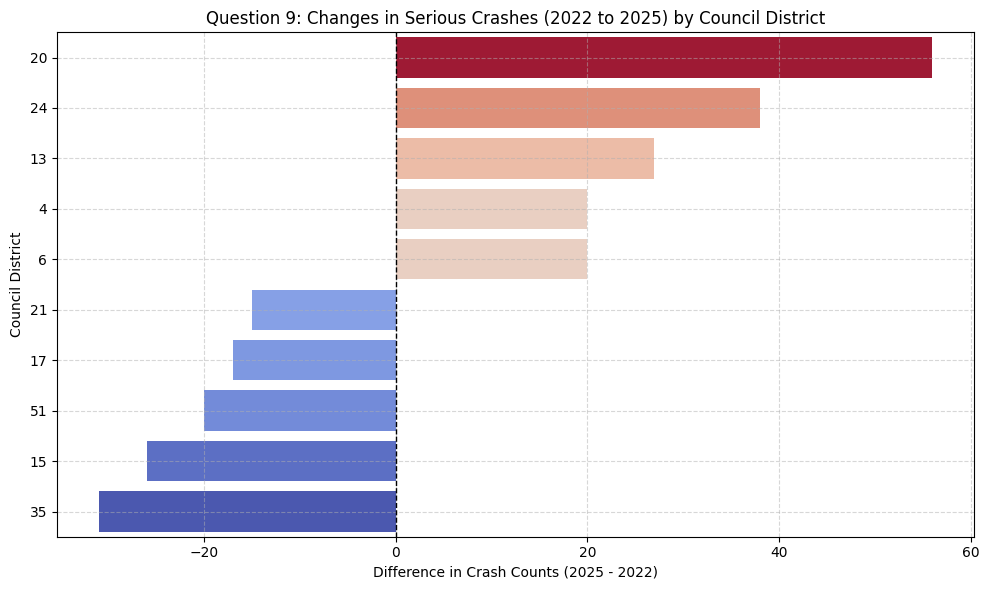

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Calculate trends
crashes_filtered = c_web[c_web['year'].isin([2022, 2025])]
trend_df = crashes_filtered.groupby(['council_final', 'year']).size().unstack(fill_value=0)
trend_df['Difference'] = trend_df[2025] - trend_df[2022]
trend_df = trend_df.sort_values(by='Difference', ascending=False)
combined_trends = pd.concat([trend_df.head(5), trend_df.tail(5)]).reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(
    data=combined_trends,
    x='Difference',
    y=combined_trends['council_final'].astype(int).astype(str),
    palette='coolwarm',
    hue='Difference',
    legend=False
)

plt.title('Question 9: Changes in Serious Crashes (2022 to 2025) by Council District', fontsize=12)
plt.xlabel('Difference in Crash Counts (2025 - 2022)')
plt.ylabel('Council District')
plt.axvline(0, color='black', linewidth=1, linestyle='--')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Why this chart:** a horizontal bar chart with a zero line makes increases (to the right) and decreases (to the left) easy to tell apart. Warm colours mark growth in crashes and cool colours mark decreases.

**What the chart shows:** Between 2022 and 2025, District 20 had the largest increase in serious crashes (from 38 to 94, +56) and District 35 the largest decrease (from 77 to 46, -31). The chart shows the five largest increases and the five largest decreases. These are descriptive changes and do not explain why crashes rose or fell.

**Limits:** this compares only the two end years, so it misses year-to-year swings, and counts are not adjusted for traffic or population. Only crashes placed in a district are counted (about 89% in 2022 and 90% in 2025).

### Question 10: Which council districts had the most affordable housing buildings completed?
**Member:** Omar Nasr

**Data used:** panel_d, districts
**Suggested chart:** horizontal bar chart of the top 10 districts, or a map (counts building records)


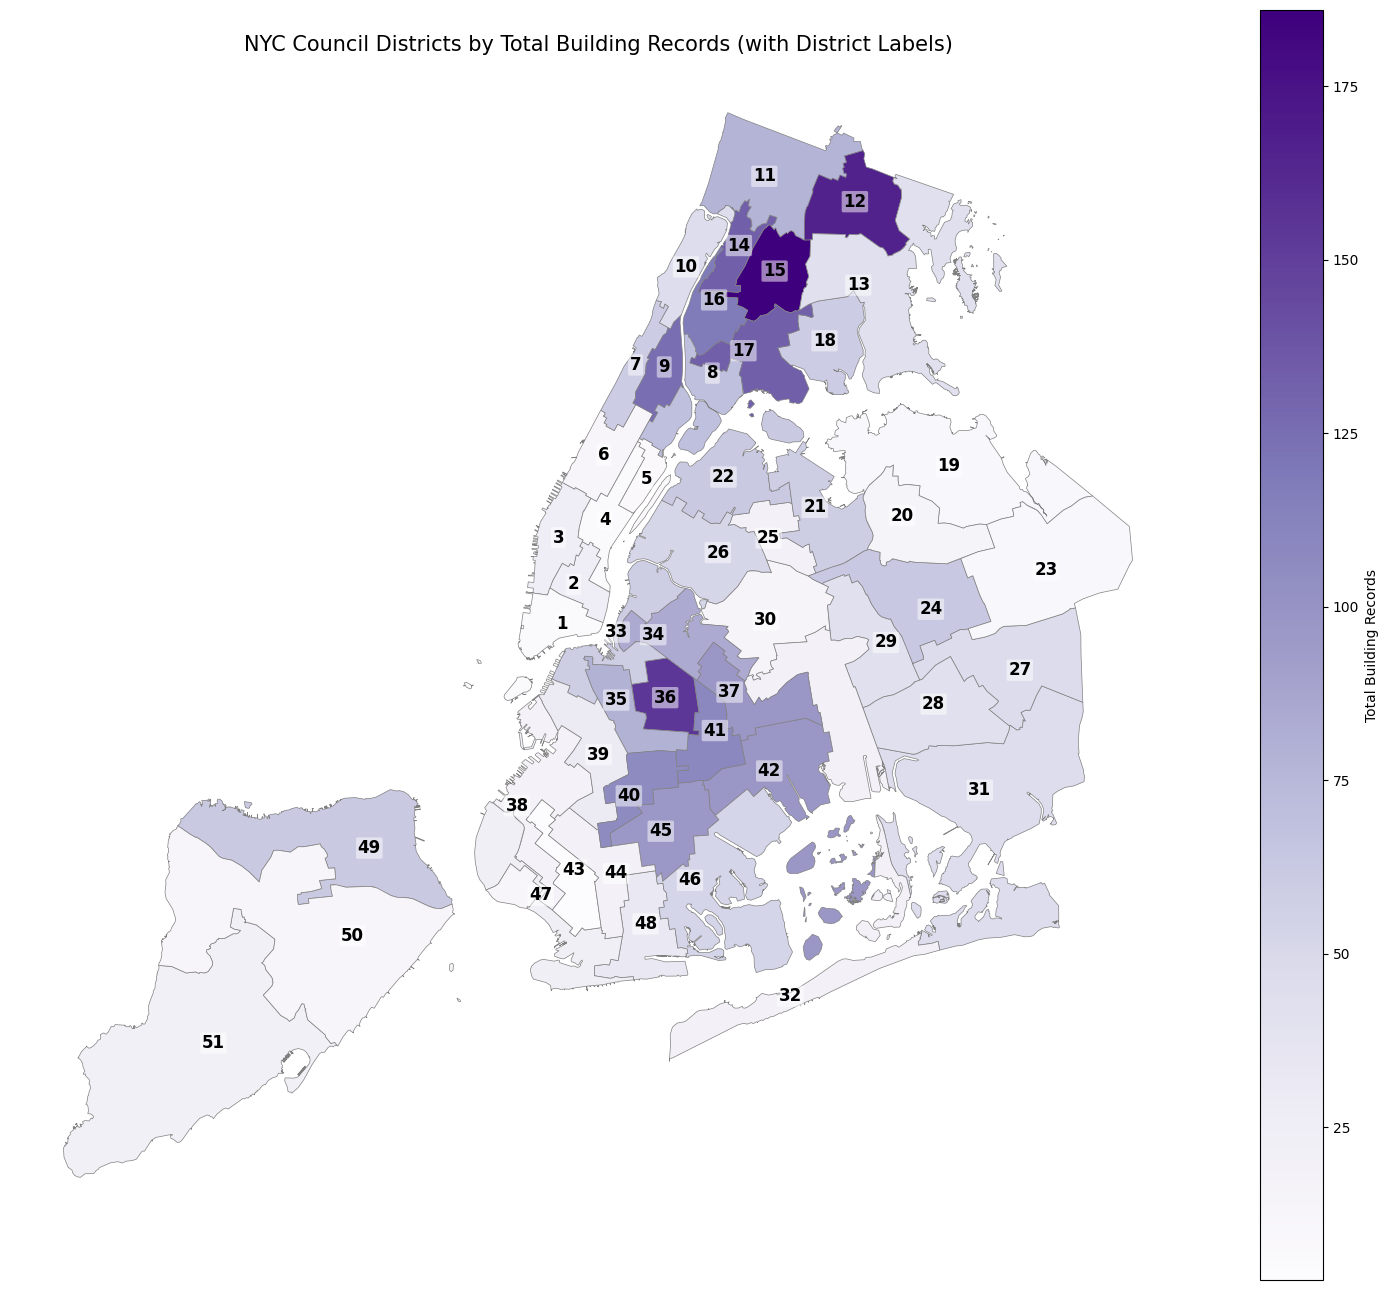

In [41]:
import geopandas as gpd
import matplotlib.pyplot as plt

gdf = districts.copy()

council_col = [col for col in gdf.columns if 'coun' in col.lower()][0]
gdf[council_col] = gdf[council_col].astype(int)
district_totals = panel_d.groupby('council_final')['building_records'].sum().reset_index()
district_totals['council_final'] = district_totals['council_final'].astype(int)

#Merge
merged_gdf = gdf.merge(district_totals, left_on=council_col, right_on='council_final', how='left')
merged_gdf['building_records'] = merged_gdf['building_records'].fillna(0)

#plot
fig, ax = plt.subplots(1, 1, figsize=(15, 13))
merged_gdf.plot(
    column='building_records',
    cmap='Purples',
    linewidth=0.5,
    ax=ax,
    edgecolor='0.5',
    legend=True,
    legend_kwds={'label': 'Total Building Records'}
)

# Calculate representative points (centroids) for each council district to plot their numbers
for idx, row in merged_gdf.iterrows():
    # Using representative_point() instead of centroid because representative_point is guaranteed
    # to lie inside the geometry polygon (which is great for irregularly shaped districts)
    rep_point = row['geometry'].representative_point()
    x, y = rep_point.x, rep_point.y

    # Place the district number as a label
    ax.text(
        x, y,
        str(int(row['council_final'])),
        fontsize=12,
        fontweight='bold',
        ha='center',
        va='center',
        color='black',
        bbox=dict(facecolor='white', alpha=0.5, edgecolor='none', boxstyle='round,pad=0.1')
    )

ax.set_title('NYC Council Districts by Total Building Records (with District Labels)', fontsize=15)
ax.axis('off')
plt.tight_layout()
plt.show()

**Why this chart:** a map shows where the buildings are across all 51 districts at once, and the district numbers on the map let a reader find any district quickly. Darker purple means more building records.

**What the map shows:** District 15 has the most affordable housing building records (186), followed by District 12 (166) and District 36 (154), with Districts 14 and 17 at 133 each. Districts 15, 12 and 17 are in the Bronx and District 36 is in Brooklyn. In total the map covers 2,957 building records completed from 2022 to 2025.

**Limits:** these are counts of building records, not units, so a large building counts once, and they are not adjusted for the size or population of each district.

## Limitations
- **Fatal crashes lack coordinates.** Only 19.7% across all years in the file have them. Of 975 fatalities in 2022 to 2025, 224 reach the district table, so district charts use severe-injury crashes, and fatal crashes are only analysed without districts (for example by month).
- **District coverage varies by year** (67.0% in 2024, 81 to 90% in other years). Crashes without a district are more often fatal (35.4% versus 2.0%) and are concentrated in 2024.
- **2023 mismatch.** The file's district agreed with the map only 77.5% of the time. The cause is unknown.
- **Housing completion dates.** 1,666 buildings (17.4%) have none and are left out of time charts.
- **Missing Building IDs.** 1,949 housing records have no Building ID, so buildings are counted as records.
- **Staten Island** has only a few housing records per year, so its yearly trend is not reliable.
- **Counts, not rates.** Districts differ in size and density, so both measures grow with district size. Results show association only, not cause.
- **Midnight crash times.** Some crashes recorded at exactly 00:00 may have an unknown time, so the midnight hour in Question 1 may be inflated.
- **Street names.** About 19% of crashes have no street name and are left out of Question 8. Only a final abbreviation (such as AVE) was spelled out, so other spelling variants of the same street can remain separate, and streets with the same name in different boroughs are counted together.

## Alternative dataset considered
We tested DOB NOW: Build, Job Application Filings (dataset w9ak-ipjd) in place of the housing data. Filtered on the server to New Building filings from 2022 to 2025 with coordinates, it gave 39,871 rows, all placed in a district. Its association with severe-injury crashes per district was weaker (rank correlation 0.16 for filings, 0.49 for proposed units) than that of the H2 affordable units (0.56). Within boroughs the picture was mixed, and in four of the five boroughs filings rose every year while crashes stayed roughly flat. Because the evidence did not favour it, and H2 was already cleaned and integrated, we kept H2.

In [42]:
'''import shutil
shutil.make_archive('Data_Engineering_Project_1_Data', 'zip', 'data')
from google.colab import files
files.download('Data_Engineering_Project_1_Data.zip')'''

"import shutil\nshutil.make_archive('Data_Engineering_Project_1_Data', 'zip', 'data')\nfrom google.colab import files\nfiles.download('Data_Engineering_Project_1_Data.zip')"

## Prompts used
We used claude to choose the datasets, plan the cleaning and draft the code for the charts. Examples of what we asked: how to check whether the midnight crashes were really missing times, whether any empty columns had been wrongly filled with zero, whether street names were standardised, and for a chart that shows a real relation between the two datasets. We ran every suggestion ourselves and checked it against the real output before keeping it.

## Dataset links
- Housing H2: https://data.cityofnewyork.us/Housing-Development/Affordable-Housing-Production-by-Building/hg8x-zxpr/about_data
- Crashes T4: https://data.cityofnewyork.us/Transportation/Serious-Injury-Response-Tracking-Analysis-Program-/xeqp-qz8h/about_data
- Supporting data: City Council Districts, NYC Department of City Planning, NYC Open Data (872g-cjhh), version 26c: https://data.cityofnewyork.us/d/872g-cjhh